In [8]:
import pandas as pd

df = pd.read_parquet('repacts.parquet')
print(f'Total documents: {len(df):,}')
print(f'Columns: {df.columns.tolist()}')

df.head()
# doc = ra.sort_values('year', ascending=False)
# found = doc[doc['content'].str.contains('tuberculosis')].iloc[10]
# print(f'Title: {found['title']}')
# print(f'Source: {found['source']}')
# print(f'Year: {found['year']}')
# print(f'Path: {found['path']}')
# print(f'\nContent:\n{found['content'][:50000000]}...')

Total documents: 12,071
Columns: ['id', 'source', 'year', 'month', 'path', 'basename', 'title', 'content']


,id,source,year,month,path,basename,title,content
0,repacts:datasets/markdown/repacts/1946/ra1946.md,repacts,1946,None,datasets/markdown/repacts/1946/ra1946.md,ra1946,Ra1946,NUMBER\n\nTITLE\n\n [Republic Act No. 89](ra_8...
1,repacts:datasets/markdown/repacts/1946/ra_10_1...,repacts,1946,None,datasets/markdown/repacts/1946/ra_10_1946.md,ra_10_1946,REPUBLIC ACT No. 10,**REPUBLIC ACT No. 10**\n\n AN ACT PENALIZING ...
2,repacts:datasets/markdown/repacts/1946/ra_11_1...,repacts,1946,None,datasets/markdown/repacts/1946/ra_11_1946.md,ra_11_1946,REPUBLIC ACT No. 11,**REPUBLIC ACT No. 11**\n\n AN ACT TO PROHIBIT...
3,repacts:datasets/markdown/repacts/1946/ra_12_1...,repacts,1946,None,datasets/markdown/repacts/1946/ra_12_1946.md,ra_12_1946,REPUBLIC ACT No. 12,**REPUBLIC ACT No. 12**\n\n **An Act Amending ...
4,repacts:datasets/markdown/repacts/1946/ra_13_1...,repacts,1946,None,datasets/markdown/repacts/1946/ra_13_1946.md,ra_13_1946,REPUBLIC ACT No. 13,**REPUBLIC ACT No. 13**\n\n **An Act to Amend ...


In [9]:
df = df.query('year >= 2016 and year <= 2022')
df = df[df['basename'].str.contains(r'^ra.*')]
print(f'Total documents: {len(df):,}')
print(f'Columns: {df.columns.tolist()}')
df.head()

Total documents: 1,186
Columns: ['id', 'source', 'year', 'month', 'path', 'basename', 'title', 'content']


,id,source,year,month,path,basename,title,content
10500,repacts:datasets/markdown/repacts/2016/ra2016.md,repacts,2016,None,datasets/markdown/repacts/2016/ra2016.md,ra2016,Ra2016,NUMBER\n\nTITLE\n\n Republic Act No. 10924 \n...
10501,repacts:datasets/markdown/repacts/2016/ra_1074...,repacts,2016,None,datasets/markdown/repacts/2016/ra_10740_2016.md,ra_10740_2016,Ra 10740 2016,Sixteenth Congress Third Regular Session\n\n *...
10502,repacts:datasets/markdown/repacts/2016/ra_1074...,repacts,2016,None,datasets/markdown/repacts/2016/ra_10741_2016.md,ra_10741_2016,Ra 10741 2016,Sixteenth Congress Third Regular Session\n\n *...
10503,repacts:datasets/markdown/repacts/2016/ra_1074...,repacts,2016,None,datasets/markdown/repacts/2016/ra_10742_2016.md,ra_10742_2016,Ra 10742 2016,Sixteenth Congress Third Regular Session\n\n *...
10504,repacts:datasets/markdown/repacts/2016/ra_1074...,repacts,2016,None,datasets/markdown/repacts/2016/ra_10743_2016.md,ra_10743_2016,Ra 10743 2016,Sixteenth Congress Third Regular Session\n\n *...


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1186 entries, 10500 to 11696
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   id        1186 non-null   object
 1   source    1186 non-null   object
 2   year      1186 non-null   int64 
 3   month     0 non-null      object
 4   path      1186 non-null   object
 5   basename  1186 non-null   object
 6   title     1186 non-null   object
 7   content   1186 non-null   object
dtypes: int64(1), object(7)
memory usage: 83.4+ KB


In [11]:
df['content'].iloc[0]

'NUMBER\n\nTITLE\n\n Republic Act No. 10924  \nDecember 22, 2016\n\nAn Act Appropriating Funds for the Operation of the Government of the Republic of the Philippines From January One to December Thirty-One, Two Thousand and Seventeen, and for Other Purposes\n\n [Republic Act No. 10923](ra_10923_2016.html)  \nOctober 15, 2016\n\nAn Act Postponing the October 2016 Barangay and Sangguniang Kabataan Elections, Amending for the Purpose Replublic Act No. 9164, as Amended By Republic Act No. 9340 and Republic Act No. 10656 Prescribing Additional Rules Governing the Conduct of Barangay and Sangguniang Kabataan Elections and for Other Purposes\n\n[pdf/ra_10923_2016.pdf](pdf/ra_10923_2016.pdf)\n\n [IRR of 10868](irr_10868_2016.html)  \nSeptember 16, 2016\n\nImplementing Rules and Regulation of [Republic Act No. 10868](ra_10868_2024.html)\n\n [Republic Act No. 10922](ra_10922_2016.html)  \nJuly 22, 2016\n\nAn Act Declaring the Second Week of November of Every Year as Economic and Financial Litera

In [12]:
# include only from june 30 2016 to june 30 2022
# filter out aggregation of RAs within a year (RA2016, RA2017...)
df = df[~df['basename'].str.contains(r'ra\d{4}', case=False)]
len(df)

1179

In [13]:
# unfortunately some entries like ra_11449_2019 and ra_11905_2022 have stripped data and did not contain the full text
def read_file(filename: str) -> str:
    with open(filename, 'r') as file:
        return file.read()
    return ''

df.loc[df['basename'] == 'ra_11449_2019', 'content'] = read_file('ra_1149_2019_complete.txt')
df.loc[df['basename'] == 'ra_11905_2022', 'content'] = read_file('ra_11905_2022_complete.txt')
df.loc[df['basename'] == 'ra_10766_2016', 'content'] = read_file('ra_10766_2016_complete.txt')
df.loc[df['basename'] == 'ra_10771_2016', 'content'] = read_file('ra_10771_2016_complete.txt')
df.loc[df['basename'] == 'ra_11035_2018', 'content'] = read_file('ra_11035_2018_complete.txt')
df.loc[df['basename'] == 'ra_11453_2019', 'content'] = read_file('ra_11453_2019_complete.txt')
df.loc[df['basename'] == 'ra_11900_2022', 'content'] = read_file('ra_11900_2022_complete.txt')
df.loc[df['basename'] == 'ra_11904_2022', 'content'] = read_file('ra_11904_2022_complete.txt')
df.loc[df['basename'] == 'ra_10967_2018', 'content'] = read_file('ra_10967_2018_complete.txt') # missing the header 'begun and held...'
df.loc[df['basename'] == 'ra_10814_2016', 'content'] = read_file('ra_10814_2016_complete.txt') # corrected typo on approved date ('Lapsed into law on MAY 13 2106')

In [14]:
# temp1 = df[df['content'].str.contains(r'.*Approved:\s?([A-Za-z]+)\s?\d+,?\s?(\d{4}).*', case=False) | df['content'].str.contains(r'\[\s?REPUBLIC ACT NO. \d+,\s([A-Za-z]+)\s\d{1,2},\s\d{4}\s\]', case=False) | df['content'].str.contains(r'Lapsed into law on ([A-Za-z]+)\s\d{1,2},?\s\d{4}', case=False) | df['content'].str.contains(r'.*was passed by.*', case=False)]
# temp1

In [15]:
# temp2 = df[~(df['content'].str.contains(r'.*Approved:\s?([A-Za-z]+)\s?\d+,?\s?(\d{4}).*', case=False) | df['content'].str.contains(r'\[\s?REPUBLIC ACT NO. \d+,\s([A-Za-z]+)\s\d{1,2},\s\d{4}\s\]', case=False) | df['content'].str.contains(r'Lapsed into law on ([A-Za-z]+)\s\d{1,2},?\s\d{4}', case=False) | df['content'].str.contains(r'.*was passed by.*', case=False))]
# temp2

In [16]:
df = df[(df['content'].str.contains(r'\(Sgd\.\)\s\*{0,3}RODRIGO ROA DUTERTE\*{0,3}', case=False) | df['content'].str.contains(r'\*{0,3}RODRIGO ROA DUTERTE\*{0,3}\s?\n?President of the Philippines', case=False) | df['content'].str.contains(r'without the signature of the President', case=False)) & ~df['content'].str.contains(r'.*BE\**NIGNO S\. AQUINO,?\s?[III]?.*\n?President of the Philippines', case=False)]
len(df)

# excluding Marcos's from 2022 (2 rows)

994

In [17]:
# temp = df[~(df['content'].str.contains(r'\(Sgd\.\)\s\*{0,3}RODRIGO ROA DUTERTE\*{0,3}', case=False) | df['content'].str.contains(r'\*{0,3}RODRIGO ROA DUTERTE\*{0,3}\s?\n?President of the Philippines', case=False) | df['content'].str.contains(r'without the signature of the President', case=False)) & ~df['content'].str.contains(r'.*BE\**NIGNO S\. AQUINO,?\s?[III]?.*\n?President of the Philippines', case=False)].sort_values('year', ascending=True)
# len(temp)

In [18]:
# print('\n'.join(df[df['basename'] == 'ra_11886_2022']['content'].to_list()))

In [19]:
# df[df['content'].str.contains(''ll')]

In [20]:
# supplying approved date

find_date = df[df['content'].str.contains(r'Approved[:\.]?\s?(Lapsed into law on\s)?[A-Za-z]+\s\d{1,2},?\s\d{4}')]
# find_date = df[df['content'].str.contains(r'Begun and held.*two thousand (sixteen|seventeen|eighteen|nineteen|twenty)\s?(one)?')]
len(find_date)

C:\Users\crsst\AppData\Local\Temp\ipykernel_25552\2757263229.py:3: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  find_date = df[df['content'].str.contains(r'Approved[:\.]?\s?(Lapsed into law on\s)?[A-Za-z]+\s\d{1,2},?\s\d{4}')]


990

In [21]:
# df[~df['content'].str.contains(r'Approved[:\.]?\s?(Lapsed into law on\s)?[A-Za-z]+\s\d{1,2},?\s\d{4}')]

In [22]:
df[['month', 'day', 'year_extracted']] = df['content'].str.extract(r'Approved[:\.]?\s?(?:Lapsed into law on\s)?([A-Za-z]+)\s(\d{1,2}),?\s(\d{4})')

# bool1 = df['month'].isnull()
# df[bool1]

# manually supplying for various reasons
df.loc[df['basename'] == 'ra_11425_2019', ['month', 'day', 'year_extracted']] = ['aug', '22', '2019'] # ref: https://laws.chanrobles.com/republicacts/115_republicacts.php?id=11120 format 'Approved: AUG 22 2019'
df.loc[df['basename'] == 'ra_11610_2021', ['month', 'day', 'year_extracted']] = ['dec', '10', '2021'] # ref: https://lawphil.net/statutes/repacts/ra2021/ra_11610_2021.html format '[ REPUBLIC ACT NO. 11610, December 10, 2021 ]'
df.loc[df['basename'] == 'ra_11707_2022', ['month', 'day', 'year_extracted']] = ['apr', '17', '2022'] # ref: https://lawphil.net/statutes/repacts/ra2022/ra_11707_2022.html format '[ REPUBLIC ACT NO. 11707, April 17, 2022 ]'
df.loc[df['basename'] == 'ra_11862_2022', ['month', 'day', 'year_extracted']] = ['jun', '23', '2022'] # ref: https://lawphil.net/statutes/repacts/ra2022/ra_11862_2022.html format '[ REPUBLIC ACT NO. 11862, June 23, 2022 ]'

# bool1 = df['month'].isnull()
# df[bool1]

In [23]:
# df['approved_date'] = pd.to_datetime(df[['year', 'month', 'day']])
df['month'] = df['month'].str.lower().str[:3]
df['month']

10683    oct
10685    apr
10686    apr
10687    jul
10688    aug
        ... 
11690    jul
11691    jul
11692    jul
11693    jul
11694    jan
Name: month, Length: 994, dtype: object

In [24]:
df['approved_date'] = pd.to_datetime(df.year.astype(str) + ' ' + df.month.astype(str) + ' ' + df.day.astype(str))
df['approved_date']

C:\Users\crsst\AppData\Local\Temp\ipykernel_25552\2566133104.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['approved_date'] = pd.to_datetime(df.year.astype(str) + ' ' + df.month.astype(str) + ' ' + df.day.astype(str))


10683   2016-10-15
10685   2017-04-21
10686   2017-04-21
10687   2017-07-14
10688   2017-08-02
           ...    
11690   2022-07-30
11691   2022-07-30
11692   2022-07-30
11693   2022-07-30
11694   2022-01-06
Name: approved_date, Length: 994, dtype: datetime64[ns]

In [25]:
df['cleaned_content'] = df['content'].str.replace('Co-Operative', 'Cooperative')
df['cleaned_content'] = df['cleaned_content'].str.replace('.html', '')
df['cleaned_content'].iloc[0]

'Seventeenth Congress First Regular Session\n\n *Begun and held in Metro Manila, on Monday, the twenty-fifth day of July, two thousand sixteen.*\n\n **REPUBLIC ACT No. 10923**\n\n **An Act Postponing the October 2016 Barangay and Sangguniang Kabataan Elections, Amending for the Purpose Republic Act No. 9164, as amended by Republic Act No. 9340 and Republic Act No. 10656, Prescribing Additional Rules Governing the Conduct of Barangay and Sangguniang Kabataan Elections and for Other Purposes**\n\n *Be it enacted by the Senate and House of Representatives of the Philippine Congress Assembled:*\n\n **Section 1.** Section 1 of Republic Act No. 9164, as amended by Republic Act No. 9340 and Republic Act No. 10656, is hereby further amended to read as follows:\n\n > "Sec. 1. *Date of Election.* - There shall be synchronized barangay and sangguniang kabataan elections, which shall be held on July 15, 2002. Subsequent synchronized barangay and sangguniang kabataan elections shall be held on the 

In [26]:
len(df)

994

In [27]:
import re
import string

def clean_text(text: str) -> str:
    text = text.lower()
    text = re.sub(r'\d+', '', text) # removes numbers
    text = re.sub(r'\s+', ' ', text).strip() # removes spaces
    text = re.sub(r'\W+', ' ', text) # matches any character that's not alphanumeric and underscore
    text = text.translate(str.maketrans('', '', string.punctuation)) # removes characters like !, ., ,, etc

    return text

df['cleaned_content'] = df['cleaned_content'].apply(clean_text)
df['cleaned_content'].iloc[0]

'seventeenth congress first regular session begun and held in metro manila on monday the twenty fifth day of july two thousand sixteen republic act no an act postponing the october barangay and sangguniang kabataan elections amending for the purpose republic act no as amended by republic act no and republic act no prescribing additional rules governing the conduct of barangay and sangguniang kabataan elections and for other purposes be it enacted by the senate and house of representatives of the philippine congress assembled section section of republic act no as amended by republic act no and republic act no is hereby further amended to read as follows sec date of election there shall be synchronized barangay and sangguniang kabataan elections which shall be held on july subsequent synchronized barangay and sangguniang kabataan elections shall be held on the last monday of october and every three years thereafter provided that the barangay and sangguniang kabataan elections on october 

In [28]:
from nltk.tokenize import word_tokenize # pyright: ignore[reportMissingTypeStubs, reportUnknownVariableType]
import typing

In [29]:
from nltk.stem import WordNetLemmatizer # pyright: ignore[reportMissingTypeStubs]
import nltk # pyright: ignore[reportMissingTypeStubs]
from nltk import pos_tag # pyright: ignore[reportMissingTypeStubs, reportUnknownVariableType]
from nltk.corpus import wordnet # pyright: ignore[reportMissingTypeStubs]

nltk.download('wordnet') # pyright: ignore[reportUnknownMemberType]
lemmatizer = WordNetLemmatizer()

def get_wordnet_pos(tag: str):
    if tag.startswith('J'):
        return wordnet.ADJ
    elif tag.startswith('V'):
        return wordnet.VERB
    elif tag.startswith('N'):
        return wordnet.NOUN
    elif tag.startswith('R'):
        return wordnet.ADV
    else:
        return wordnet.NOUN  # Default to noun

def lemmatize(text: str) -> str:
    tokens = word_tokenize(text) 
    tagged_tokens = typing.cast(list[tuple[str, str]], pos_tag(tokens)) # TODO: consider pos_tag_sents for multiple sentences
    lemmatized_tokens = [lemmatizer.lemmatize(word, get_wordnet_pos(tag)) for word, tag in tagged_tokens]
    return (' ').join(lemmatized_tokens)

# TODO: refactor use of tokens
df['cleaned_content'] = df['cleaned_content'].apply(lemmatize)
df['cleaned_content'].iloc[0]

[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\crsst\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


'seventeenth congress first regular session begin and hold in metro manila on monday the twenty fifth day of july two thousand sixteen republic act no an act postpone the october barangay and sangguniang kabataan election amend for the purpose republic act no a amend by republic act no and republic act no prescribe additional rule govern the conduct of barangay and sangguniang kabataan election and for other purpose be it enact by the senate and house of representative of the philippine congress assemble section section of republic act no a amend by republic act no and republic act no be hereby far amend to read a follow sec date of election there shall be synchronize barangay and sangguniang kabataan election which shall be hold on july subsequent synchronize barangay and sangguniang kabataan election shall be hold on the last monday of october and every three year thereafter provide that the barangay and sangguniang kabataan election on october shall be postpone to the fourth monday 

In [ ]:
from nltk.corpus import stopwords # pyright: ignore[reportMissingTypeStubs]

stop_words = typing.cast(set[str], stopwords.words('english')) # pyright: ignore[reportUnknownMemberType]

# https://lawphil.net/statutes/repacts/ra2017/ra_10933_2017.html
# contains coordinates including north/east/south/west e.g, "1	2	S	36	21	E	743.541"
stop_words.append('n')
stop_words.append('e')
stop_words.append('s')
stop_words.append('w')
stop_words.append('pt') # stands for point '"On the Northwest {NW), pts. 40 to 57, by centerline of Tucol Creek;'
stop_words.append('deg') # stands for deg 'N 08 deg. 55' W'

# excluding recurring terms not really describing themes/topics
stop_words.append('act')
stop_words.append('section')
stop_words.append('shall')
stop_words.append('may')
stop_words.append('amend')
stop_words.append('hereby')
# stop_words.append('republic')
# stop_words.append('official')
stop_words.append('year')
stop_words.append('thereof')
stop_words.append('sgd')
stop_words.append('thence')
stop_words.append('thereafter')
stop_words.append('along')
stop_words.append('day') # e.g., 'the twenty-sixth day of July'
# stop_words.append('article')
# stop_words.append('senate')
# stop_words.append('representative') # unsure, it can actually not refer to HoR
# stop_words.append('congress') # 'Be it enacted by the Senate and House of Representatives of the Philippines in Congress assembled:'
stop_words.append('upon')
stop_words.append('subsection')
# stop_words.append('provide') # 'Provided, That if there is no case filed'

# idk why there are 'x.x.x'
stop_words.append('x') # ref: https://lawphil.net/statutes/repacts/ra2017/ra_10963_2017.html '(A) x x x'

# removing 'non-'
stop_words.append('non')

# abbreviations
stop_words.append('du') # stands for 'Distribution Utility' ref: https://lawphil.net/statutes/repacts/ra2022/ra_11646_2022.html

# alphabet, often used as lists
stop_words.extend([chr(i) for i in range(ord('a'), ord('z') + 1)])

# numbers as words
stop_words.extend(['zero', 'one', 'two', 'three', 'four', 'five', 'six', 'seven', 'eight', 'nine', 'ten'])

# days
stop_words.extend(['monday', 'tuesday', 'wednesday', 'thursday', 'friday', 'saturday', 'sunday'])

# months
stop_words.extend(['january', 'february', 'march', 'april', 'may', 'june', 'july', 'august', 'september', 'october', 'november', 'december'])

print(stop_words)

def remove_stopwords(text: str) -> str:
    tokens = word_tokenize(text)
    filtered_text = (' ').join([word for word in tokens if word not in stop_words])
    return filtered_text

df['cleaned_content'] = df['cleaned_content'].apply(remove_stopwords)
df['cleaned_content'].iloc[0]

# df[df['cleaned_content'].str.contains("amend")]

['a', 'about', 'above', 'after', 'again', 'against', 'ain', 'all', 'am', 'an', 'and', 'any', 'are', 'aren', "aren't", 'as', 'at', 'be', 'because', 'been', 'before', 'being', 'below', 'between', 'both', 'but', 'by', 'can', 'couldn', "couldn't", 'd', 'did', 'didn', "didn't", 'do', 'does', 'doesn', "doesn't", 'doing', 'don', "don't", 'down', 'during', 'each', 'few', 'for', 'from', 'further', 'had', 'hadn', "hadn't", 'has', 'hasn', "hasn't", 'have', 'haven', "haven't", 'having', 'he', "he'd", "he'll", 'her', 'here', 'hers', 'herself', "he's", 'him', 'himself', 'his', 'how', 'i', "i'd", 'if', "i'll", "i'm", 'in', 'into', 'is', 'isn', "isn't", 'it', "it'd", "it'll", "it's", 'its', 'itself', "i've", 'just', 'll', 'm', 'ma', 'me', 'mightn', "mightn't", 'more', 'most', 'mustn', "mustn't", 'my', 'myself', 'needn', "needn't", 'no', 'nor', 'not', 'now', 'o', 'of', 'off', 'on', 'once', 'only', 'or', 'other', 'our', 'ours', 'ourselves', 'out', 'over', 'own', 're', 's', 'same', 'shan', "shan't", 'she

'seventeenth congress first regular session begin hold metro manila twenty fifth thousand sixteen republic postpone barangay sangguniang kabataan election purpose republic republic republic prescribe additional rule govern conduct barangay sangguniang kabataan election purpose enact senate house representative philippine congress assemble republic republic republic far read follow sec date election synchronize barangay sangguniang kabataan election hold subsequent synchronize barangay sangguniang kabataan election hold last every provide barangay sangguniang kabataan election postpone fourth subsequent synchronize barangay sangguniang kabataan election hold second every republic republic read follow sec assumption office term office barangay sangguniang kabataan official elect commence noon next follow election provide however term office barangay sangguniang kabataan official elect election subsequently commmence noon next follow election hold successor duly elect qualify incumbent ba

('provide', 7174)
('representative', 5964)
('philippine', 5936)
('house', 5794)
('service', 4861)
('senate', 4652)
('public', 4621)
('grantee', 4490)
('government', 4202)
('national', 3983)
('president', 3964)
('city', 3840)
('law', 3826)
('franchise', 3815)
('provision', 3811)
('general', 3661)
('include', 3408)
('secretary', 3378)
('congress', 3288)
('program', 3190)
('republic', 3163)
('regulation', 2828)
('board', 2813)
('rule', 2681)
('development', 2662)


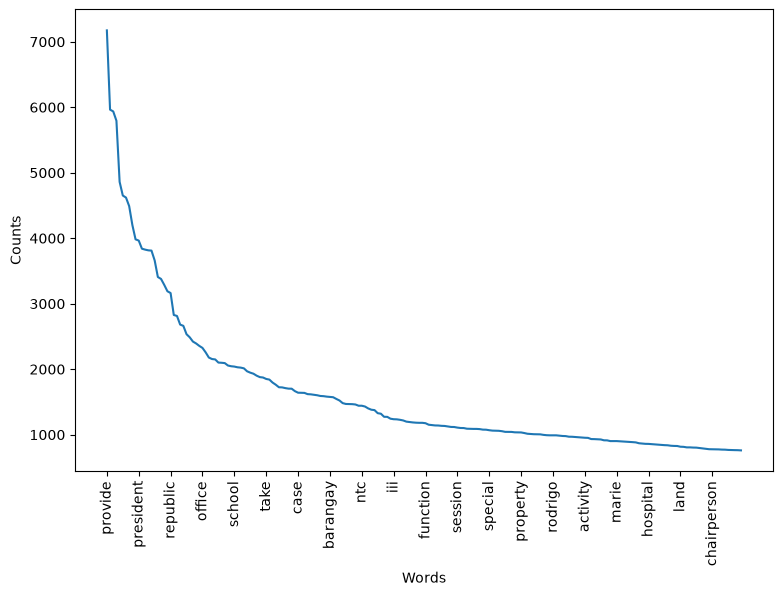

In [39]:
from collections import Counter
import matplotlib.pyplot as plt
import seaborn as sns

def plot_counts(counts, n_words = 200, by_x = 10):
    counts = pd.DataFrame(counts.items(), columns = ('word', 'count'))
    counts.sort_values('count', ascending = False, inplace = True)

    _, ax = plt.subplots(figsize = (9, 6))
    g = sns.lineplot(x = 'word', y = 'count', data = counts[:n_words], ax = ax)
    g.set(xlabel = "Words", ylabel = "Counts")
    plt.xticks(rotation = 90, ticks = range(0, n_words, by_x));

total_tokens_counter = Counter()
total_tokens: list[str] = []
for cleaned_content in df['cleaned_content']:
    tokens = word_tokenize(cleaned_content)
    total_tokens.extend(tokens)
    tokens_count = Counter(tokens)
    total_tokens_counter.update(tokens_count)

for entry in total_tokens_counter.most_common(25):
    print(entry)
plot_counts(total_tokens_counter)

In [75]:
# I don't need contractions based on this list (manually searched thru content column) https://en.wikipedia.org/wiki/Contraction_(grammar)

In [43]:
from nltk import collocations

finder = collocations.BigramCollocationFinder.from_words(total_tokens)

bigrams = finder.ngram_fd

bigrams = [(word, pair, count) for (word, pair), count in bigrams.items()]
bigrams = pd.DataFrame(bigrams, columns = ('word', 'pair', 'count'))
bigrams.sort_values('count', ascending = False, inplace = True)
bigrams.head(10)

,word,pair,count
30,house,representative,5397
201,rule,regulation,2342
276,president,philippine,1213
678,local,government,1177
257,speaker,house,1086
32,philippine,congress,1069
29,senate,house,1057
253,president,senate,1047
240,take,effect,1030
264,secretary,senate,1029


In [47]:
# pointwise mutual information
measures = collocations.BigramAssocMeasures()

bigram_pmi = finder.score_ngrams(measures.pmi)
bigram_pmi = [(word, pair, val) for (word, pair), val in bigram_pmi]
bigram_pmi = pd.DataFrame(bigram_pmi, columns = ('word', 'pair', 'pmi'))
bigram_pmi.sort_values('pmi', ascending = False, inplace = True)
bigram_pmi.tail(10)

,word,pair,pmi
209114,law,house,-4.879863
209115,city,representative,-4.926853
209116,representative,city,-4.926853
209117,philippine,president,-4.965914
209118,national,philippine,-4.972813
209119,general,provide,-5.124482
209120,public,house,-5.152231
209121,representative,public,-5.193951
209122,provide,senate,-5.470095
209123,provide,house,-5.786803


In [48]:
bigram_pmi[bigram_pmi['pmi'] > bigram_pmi['pmi'].quantile(0.75)].sample(10)

,word,pair,pmi
21,anime,manga,19.522103
14850,bllm,tungawan,11.362231
49476,leadership,preserve,7.703520
38046,voice,audio,8.579588
4998,orion,pilar,14.352178
51843,minster,member,7.546971
51154,niasd,develop,7.590442
30508,engineer,architect,9.269437
44756,dswd,eccd,8.035268
37603,correspond,salary,8.611010


In [76]:
del df['content'] # retaining only the cleaned tokens so it's easier to browse the csv file
df.to_csv('cleaned_corpus.csv', index=False)